In [1]:
import pandas as pd
import numpy as np

# Load daily revenue data
df = pd.read_csv("daily_wide_revenue.csv")

# Convert date column
df["date"] = pd.to_datetime(df["date"])

# Check dataset
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Shape: (180, 4)

Columns:
['date', 'North', 'South', 'West']

First 5 rows:


,date,North,South,West
0,2025-01-01,50651.59,48937.65,60109.02
1,2025-01-02,54431.06,52101.37,62082.51
2,2025-01-03,62516.51,53274.36,57028.24
3,2025-01-04,67241.10,60980.94,65800.24
4,2025-01-05,66825.20,66908.57,69358.06



Missing values:
date     0
North    0
South    0
West     0
dtype: int64


In [2]:
# Define treatment date
intervention_date = pd.Timestamp("2025-05-01")

# Create pre and post periods
df["period"] = np.where(
    df["date"] < intervention_date,
    "Pre",
    "Post"
)

# Calculate average control revenue
df["Control"] = df[["South", "West"]].mean(axis=1)

# Calculate average revenue by period
did_summary = df.groupby("period")[
    ["North", "Control"]
].mean()

display(did_summary)

# Extract values
north_pre = did_summary.loc["Pre", "North"]
north_post = did_summary.loc["Post", "North"]

control_pre = did_summary.loc["Pre", "Control"]
control_post = did_summary.loc["Post", "Control"]

# Calculate changes
north_change = north_post - north_pre
control_change = control_post - control_pre

# Difference-in-Differences
did_effect = north_change - control_change

print("North Pre Revenue:", round(north_pre, 2))
print("North Post Revenue:", round(north_post, 2))
print("Control Pre Revenue:", round(control_pre, 2))
print("Control Post Revenue:", round(control_post, 2))

print("\nNorth Change:", round(north_change, 2))
print("Control Change:", round(control_change, 2))
print("DiD Effect:", round(did_effect, 2))

,North,Control
period,,
Post,66366.439667,63828.858833
Pre,61944.391583,61347.117458


North Pre Revenue: 61944.39
North Post Revenue: 66366.44
Control Pre Revenue: 61347.12
Control Post Revenue: 63828.86

North Change: 4422.05
Control Change: 2481.74
DiD Effect: 1940.31


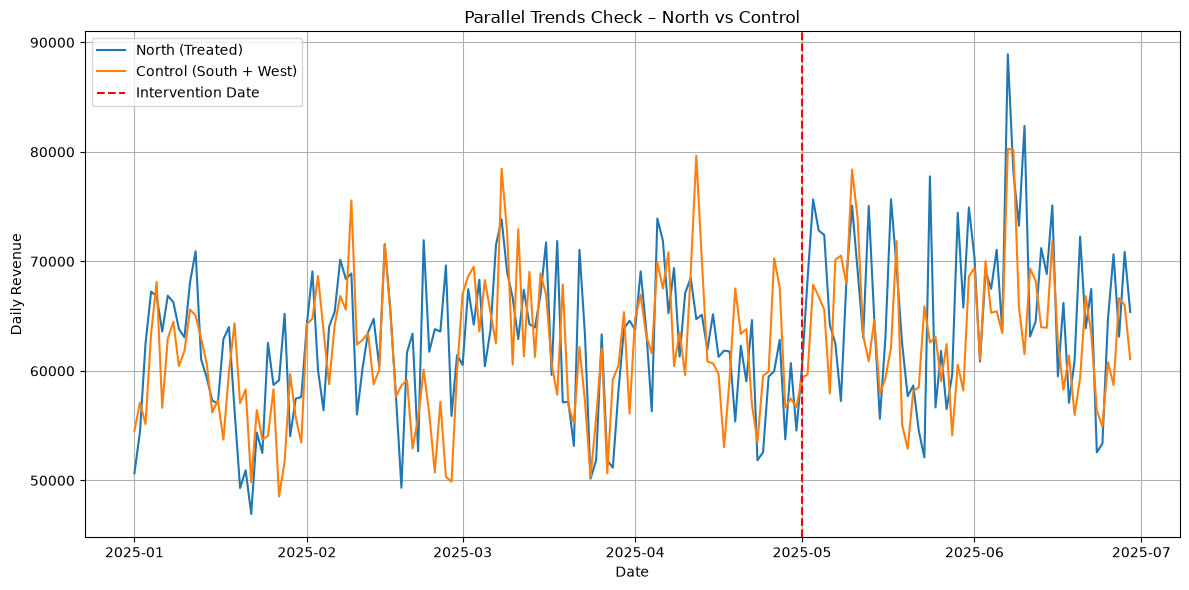

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(df["date"], df["North"], label="North (Treated)")
plt.plot(df["date"], df["Control"], label="Control (South + West)")

plt.axvline(
    intervention_date,
    color="red",
    linestyle="--",
    label="Intervention Date"
)

plt.title("Parallel Trends Check – North vs Control")
plt.xlabel("Date")
plt.ylabel("Daily Revenue")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [4]:
# Create DiD results table

did_results = pd.DataFrame({
    "Metric": [
        "North Pre Revenue",
        "North Post Revenue",
        "Control Pre Revenue",
        "Control Post Revenue",
        "North Revenue Change",
        "Control Revenue Change",
        "DiD Effect"
    ],
    "Value": [
        north_pre,
        north_post,
        control_pre,
        control_post,
        north_change,
        control_change,
        did_effect
    ]
})

# Save results
did_results.to_csv("did_results.csv", index=False)

display(did_results)

print("DiD results saved successfully!")

,Metric,Value
0,North Pre Revenue,61944.391583
1,North Post Revenue,66366.439667
2,Control Pre Revenue,61347.117458
3,Control Post Revenue,63828.858833
4,North Revenue Change,4422.048083
5,Control Revenue Change,2481.741375
6,DiD Effect,1940.306708


DiD results saved successfully!


In [6]:
# Create model comparison table

comparison = pd.DataFrame({
    "Method": [
        "Synthetic Control Method (SCM)",
        "Double Machine Learning (DML)",
        "Difference-in-Differences (DiD)"
    ],
    "Estimated Effect": [
        2537.58,
        1953.85,
        1940.31
    ],
    "Interpretation": [
        "Average post-treatment revenue gap",
        "Estimated effect for a 10-unit price increase",
        "Difference in average revenue changes"
    ]
})

display(comparison)

# Save comparison
comparison.to_csv("scm_dml_did_comparison.csv", index=False)

print("Model comparison saved successfully!")

,Method,Estimated Effect,Interpretation
0,Synthetic Control Method (SCM),2537.58,Average post-treatment revenue gap
1,Double Machine Learning (DML),1953.85,Estimated effect for a 10-unit price increase
2,Difference-in-Differences (DiD),1940.31,Difference in average revenue changes


Model comparison saved successfully!
